# Task A — Nine misleading claims, solved one by one

CDB601220 · Week 3. Work through the cells from top to bottom. Every dataset is loaded from the **data/** folder beside this notebook. All data are synthetic, supplied with the assignment. Charts and written answers stay inside the notebook; no output files are created.

## 1. Import libraries and locate the data folder

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

DATA = Path('data')
assert DATA.is_dir(), 'Open this notebook inside task3, beside the data folder.'
sns.set_theme(style='whitegrid', palette=['#0072B2', '#D55E00', '#009E73'])
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.ioff()
BLUE, ORANGE, GREEN = '#0072B2', '#D55E00', '#009E73'
SOURCE = 'Source: synthetic CDB601220 Week 3 assignment data.'

## A1. Helmet injury rates
### Load and inspect the riders

In [2]:
helmets = pd.read_csv(DATA / 'case01_helmet_rickshaw.csv')
display(helmets.head())
print('Riders:', len(helmets))

,rider_id,helmet_grade,road_type,trips,head_injuries,avg_speed_kph,months_experience
0,R-0001,Standard,Motorway,100,1,73.2,59
1,R-0002,Standard,Motorway,100,1,75.7,39
2,R-0003,Standard,Motorway,100,4,70.7,29
3,R-0004,Standard,Motorway,100,0,70.6,41
4,R-0005,Standard,Motorway,100,0,69.9,23


Riders: 1000


### Calculate the published pooled rates

In [3]:
totals = helmets.groupby('helmet_grade')[['trips', 'head_injuries']].sum()
totals['injuries_per_1000'] = totals.head_injuries / totals.trips * 1000
totals = totals.reindex(['Standard', 'Premium'])
display(totals)
assert np.allclose(totals.injuries_per_1000, [2.15, 5.40])

,trips,head_injuries,injuries_per_1000
helmet_grade,,,
Standard,60000,129,2.15
Premium,40000,216,5.40


### Reproduce the misleading pooled chart

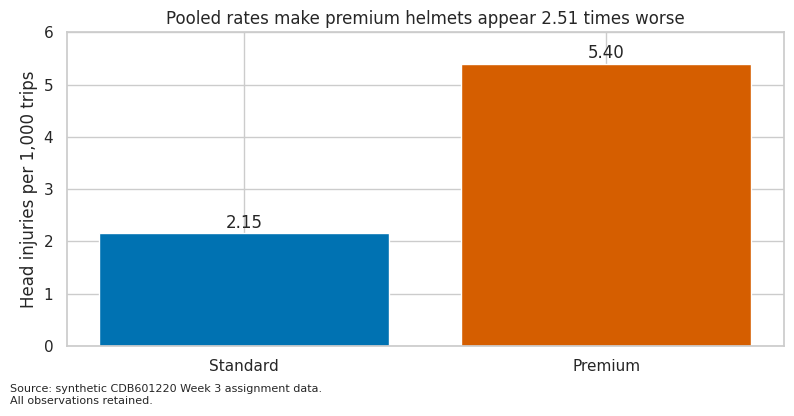

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(totals.index, totals.injuries_per_1000, color=[BLUE, ORANGE])
ax.set(ylim=(0, 6), ylabel='Head injuries per 1,000 trips',
       title='Pooled rates make premium helmets appear 2.51 times worse')
for i, value in enumerate(totals.injuries_per_1000):
    ax.text(i, value + 0.1, f'{value:.2f}', ha='center')
fig.text(0.01, -0.03, SOURCE + '\n' + 'All observations retained.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Test road exposure and the experience decoy

In [5]:
road_totals = helmets.groupby(['road_type', 'helmet_grade'])[['trips', 'head_injuries']].sum()
road_rates = (1000 * road_totals.head_injuries / road_totals.trips).unstack()
motorway_trips = helmets.loc[helmets.road_type == 'Motorway'].groupby('helmet_grade').trips.sum()
display(road_rates)
display((100 * motorway_trips / totals.trips).rename('motorway_percent'))
display(helmets.groupby('helmet_grade')[['months_experience', 'avg_speed_kph']].mean())
display(helmets.groupby(['road_type', 'helmet_grade']).avg_speed_kph.mean())

helmet_grade,Premium,Standard
road_type,,
City arterial,2.2,3.000000
Inner-city lanes,1.0,1.394737
Motorway,6.0,8.000000


helmet_grade
Premium     85.000000
Standard     3.333333
Name: motorway_percent, dtype: float64

,months_experience,avg_speed_kph
helmet_grade,,
Premium,31.422500,66.953250
Standard,31.498333,30.223833


road_type         helmet_grade
City arterial     Premium         39.608000
                  Standard        38.016500
Inner-city lanes  Premium         25.550000
                  Standard        23.978947
Motorway          Premium         72.192353
                  Standard        70.950000
Name: avg_speed_kph, dtype: float64

### Redesign: compare within road type

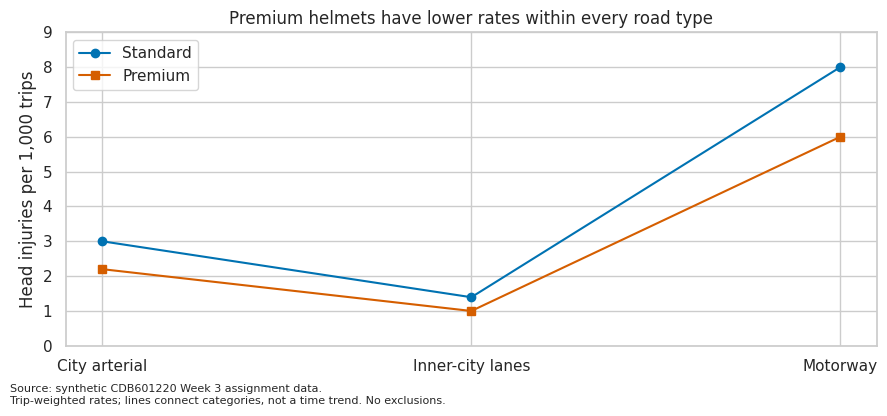

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for grade, color, marker in [('Standard', BLUE, 'o'), ('Premium', ORANGE, 's')]:
    ax.plot(road_rates.index, road_rates[grade], color=color, marker=marker, label=grade)
ax.set(ylim=(0, 9), ylabel='Head injuries per 1,000 trips',
       title='Premium helmets have lower rates within every road type')
ax.legend()
fig.text(0.01, -0.03, SOURCE + '\n' + 'Trip-weighted rates; lines connect categories, not a time trend. No exclusions.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The pooled chart invites the claim that premium helmets increase injury risk.

**Decoy:** The zero baseline rules out axis truncation. Inexperience is also a weak explanation: mean experience is 31.50 vs 31.42 months. Aggregate speed differs, but within-road speed differences are only about 1-2 km/h.

**Mechanism:** Simpson's paradox through road-exposure mix: motorway trips are 85.0% of Premium versus 3.3% of Standard. Pooled rates are 2.15 vs 5.40; within Motorway they are 8 vs 6, arterial 3 vs 2.2, lanes 1.395 vs 1 per 1,000. Road mix explains the reversal; this is not a randomized causal estimate.

**Redesign:** Compare trip-weighted injury rates within road type on one scale; all rider rows remain.

## A2. Chai sales and quiz failures
### Load the monthly records

In [7]:
chai = pd.read_csv(DATA / 'case02_chai_quizzes.csv')
display(chai.head())

,month,students_enrolled,cups_doodh_patti_sold,quiz_failures,is_exam_month,campus_open_days
0,2024-09,1765,3644,64,0,19
1,2024-10,1858,3824,65,0,21
2,2024-11,1948,4307,68,0,23
3,2024-12,2062,4349,81,1,23
4,2025-01,2216,4544,87,1,22


### Calculate Pearson correlation and the regression

In [8]:
x = chai.cups_doodh_patti_sold
y = chai.quiz_failures
fit = stats.linregress(x, y)
print(f'Raw-count Pearson r = {fit.rvalue:.4f}')
print(f'OLS: failures = {fit.intercept:.3f} + {fit.slope:.6f} × cups')

Raw-count Pearson r = 0.9820
OLS: failures = 2.434 + 0.016420 × cups


### Reproduce the published scatter

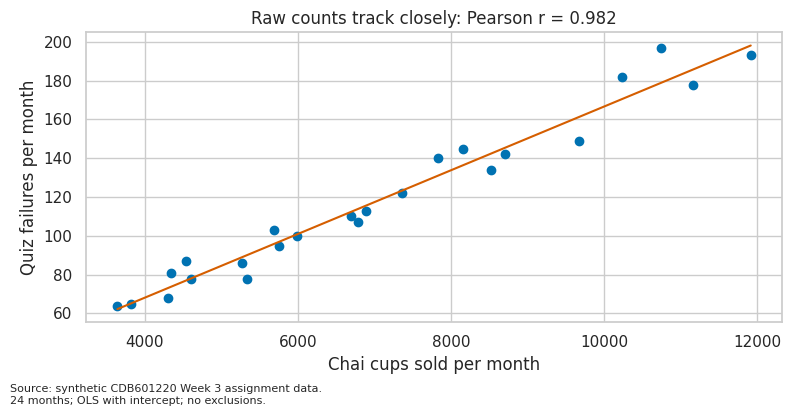

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x, y, color=BLUE)
grid = np.array([x.min(), x.max()])
ax.plot(grid, fit.intercept + fit.slope * grid, color=ORANGE)
ax.set(xlabel='Chai cups sold per month', ylabel='Quiz failures per month',
       title=f'Raw counts track closely: Pearson r = {fit.rvalue:.3f}')
fig.text(0.01, -0.03, SOURCE + '\n' + '24 months; OLS with intercept; no exclusions.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Test enrollment and exam-month explanations

In [10]:
chai['cups_per_student'] = chai.cups_doodh_patti_sold / chai.students_enrolled
chai['failures_per_100'] = 100 * chai.quiz_failures / chai.students_enrolled
rate_r = chai.cups_per_student.corr(chai.failures_per_100)
nonexam = chai.loc[chai.is_exam_month == 0]
print('Enrollment correlations:')
display(chai[['students_enrolled', 'cups_doodh_patti_sold', 'quiz_failures']].corr())
print('Non-exam-month raw r:', nonexam.cups_doodh_patti_sold.corr(nonexam.quiz_failures))
print('After per-student normalization:', rate_r)

Enrollment correlations:


,students_enrolled,cups_doodh_patti_sold,quiz_failures
students_enrolled,1.000000,0.996868,0.977491
cups_doodh_patti_sold,0.996868,1.000000,0.982023
quiz_failures,0.977491,0.982023,1.000000


Non-exam-month raw r: 0.9958839841509959
After per-student normalization: 0.2932632658392709


### Redesign: normalize both counts by enrollment

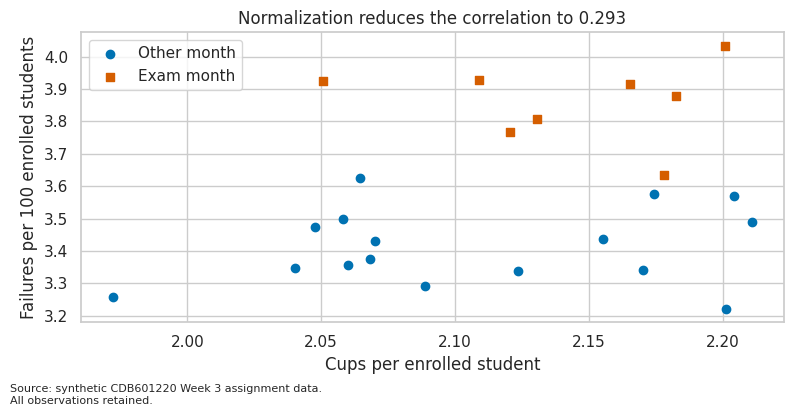

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for flag, marker, color in [(0, 'o', BLUE), (1, 's', ORANGE)]:
    group = chai.loc[chai.is_exam_month == flag]
    ax.scatter(group.cups_per_student, group.failures_per_100,
               marker=marker, color=color, label='Exam month' if flag else 'Other month')
ax.set(xlabel='Cups per enrolled student', ylabel='Failures per 100 enrolled students',
       title=f'Normalization reduces the correlation to {rate_r:.3f}')
ax.legend()
fig.text(0.01, -0.03, SOURCE + '\n' + 'All observations retained.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The chart implies that selling more chai predicts poorer student performance.

**Decoy:** Exam stress is not the main mechanism: even the 16 non-exam months have raw-count r = 0.996. Merely saying correlation is not causation does not explain that.

**Mechanism:** Exposure/size confounding: enrollment correlates 0.997 with cups and 0.977 with failures. More enrolled students create more of both counts. Per-student normalization changes r from 0.982 to 0.293; remaining association is not evidence of chai harm.

**Redesign:** Plot cups and failures per enrolled student, using marker shape as well as color for exam months.

## A3. Lahore AQI
### Load station-day data and define the policy date

In [12]:
aqi = pd.read_csv(DATA / 'case03_aqi_monitors.csv', parse_dates=['date'])
cutoff = sorted(aqi.date.unique())[60]
aqi['after'] = aqi.date >= cutoff
display(aqi.head())
print('Missing AQI readings:', aqi.aqi.isna().sum())

,date,station_id,zone,aqi,station_status,after
0,2026-01-01,LHR-01,Industrial,315.7,reporting,False
1,2026-01-02,LHR-01,Industrial,331.8,reporting,False
2,2026-01-03,LHR-01,Industrial,324.2,reporting,False
3,2026-01-04,LHR-01,Industrial,301.6,reporting,False
4,2026-01-05,LHR-01,Industrial,337.6,reporting,False


Missing AQI readings: 540


### Calculate the published means

In [13]:
daily_aqi = aqi.groupby('date').aqi.mean()
period_means = aqi.groupby('after').aqi.mean()
display(period_means.rename(index={False:'Before', True:'After'}))
print('Apparent reduction (%):', 100 * (1 - period_means[True] / period_means[False]))

after
Before    202.094621
After     137.205769
Name: aqi, dtype: float64

Apparent reduction (%): 32.10815388958017


### Reproduce the zero-based trend

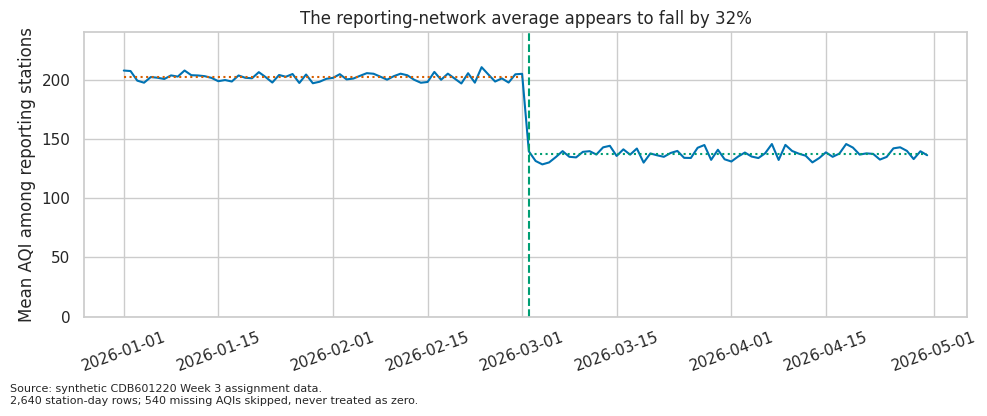

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_aqi.index, daily_aqi, color=BLUE)
ax.axvline(cutoff, color=GREEN, linestyle='--')
for post, color in [(False, ORANGE), (True, GREEN)]:
    segment = daily_aqi.loc[(daily_aqi.index >= cutoff) == post]
    ax.hlines(segment.mean(), segment.index.min(), segment.index.max(), color=color, linestyle=':')
ax.set(ylim=(0, 240), ylabel='Mean AQI among reporting stations',
       title='The reporting-network average appears to fall by 32%')
ax.tick_params(axis='x', rotation=20)
fig.text(0.01, -0.03, SOURCE + '\n' + '2,640 station-day rows; 540 missing AQIs skipped, never treated as zero.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Test whether the same stations improved

In [15]:
station_counts = aqi.groupby(['station_id', 'after']).aqi.count().unstack()
complete_ids = station_counts.index[(station_counts == 60).all(axis=1)]
balanced = aqi.loc[aqi.station_id.isin(complete_ids)]
balanced_daily = balanced.groupby('date').aqi.mean()
display(station_counts)
display(aqi.groupby(['after', 'zone']).aqi.agg(['count', 'mean']))
display(balanced.groupby('after').aqi.mean())
print('Balanced-panel rows:', len(balanced), '; stations:', len(complete_ids))

after,False,True
station_id,,
LHR-01,60,0
LHR-02,60,0
LHR-03,60,0
LHR-04,60,0
LHR-05,60,0
LHR-06,60,0
LHR-07,60,0
LHR-08,60,0
LHR-09,60,0


count        mean
after zone                          
False Arterial       360  244.697778
      Industrial     360  322.040556
      Peri-urban     240   78.949583
      Residential    360  121.642222
True  Arterial       180  245.868333
      Industrial       0         NaN
      Peri-urban     240   80.390000
      Residential    360  120.751667

after
False    137.091795
True     137.205769
Name: aqi, dtype: float64

Balanced-panel rows: 1560 ; stations: 13


### Redesign: fixed stations plus reporting counts

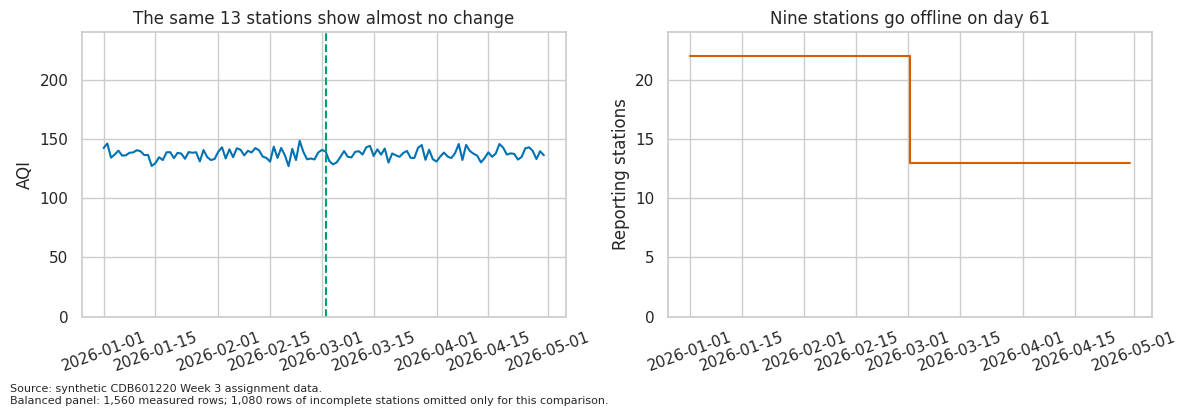

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(balanced_daily.index, balanced_daily, color=BLUE)
ax[0].axvline(cutoff, color=GREEN, linestyle='--')
ax[0].set(ylim=(0, 240), ylabel='AQI', title='The same 13 stations show almost no change')
counts = aqi.groupby('date').aqi.count()
ax[1].step(counts.index, counts, where='mid', color=ORANGE)
ax[1].set(ylim=(0, 24), ylabel='Reporting stations', title='Nine stations go offline on day 61')
for a in ax:
    a.tick_params(axis='x', rotation=20)
fig.text(0.01, -0.03, SOURCE + '\n' + 'Balanced panel: 1,560 measured rows; 1,080 rows of incomplete stations omitted only for this comparison.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The pooled line suggests that the action plan caused an approximately one-third improvement.

**Decoy:** Axis truncation is ruled out: the chart starts at zero. The same stations give 137.09 before and 137.21 after, opposing a network-wide seasonal improvement explanation.

**Mechanism:** Informative missingness/compositional selection: six industrial and three arterial stations go offline at day 61. Reporting count drops 22 to 13; 540 AQI values are missing. Pooled mean changes 202.09 to 137.21; fixed-station mean changes 137.09 to 137.21. Pollution in offline areas is unobserved, so the balanced panel cannot establish their post-policy AQI.

**Redesign:** Show a balanced-station trend beside reporting counts; retain missing rows in the source and disclose the sensitivity subset.

## A4. Matching statistics, different patterns
### Load the data

In [17]:
groups_data = pd.read_csv(DATA / 'case04_quartet_depts.csv')
display(groups_data.head())

,department,cohort_group,study_hours_per_week,final_score_out_of_20
0,Computer Science,I,20.0,15.04
1,Computer Science,I,16.0,13.95
2,Computer Science,I,26.0,14.58
3,Computer Science,I,18.0,15.81
4,Computer Science,I,22.0,15.33


### Calculate the complete published summary table

In [18]:
summary_rows = []
for name, group in groups_data.groupby('department', sort=False):
    x = group['study_hours_per_week']
    y = group['final_score_out_of_20']
    regression = stats.linregress(x, y)
    summary_rows.append({'group':name, 'n':len(group), 'mean_x':x.mean(),
        'mean_y':y.mean(), 'sd_x':x.std(ddof=0), 'sd_y':y.std(ddof=0),
        'Pearson_r':regression.rvalue, 'slope':regression.slope})
summary_table = pd.DataFrame(summary_rows).set_index('group').T
display(summary_table.round(6))

group,Computer Science,Business Administration,Electrical Engineering,Architecture
n,11.000000,11.000000,11.000000,11.000000
mean_x,18.000000,18.000000,18.000000,18.000000
mean_y,14.500909,14.500909,14.500000,14.500909
sd_x,6.324555,6.324555,6.324555,6.324555
sd_y,1.937024,1.937109,1.935933,1.936081
Pearson_r,0.816421,0.816237,0.816287,0.816521
slope,0.250045,0.250000,0.249864,0.249955


Population SD uses **ddof=0**, matching the course construction. The supplied rounded quartet data have Architecture r=0.816521, which rounds to 0.817; the assignment’s 0.816 is approximate.

### Redesign: show every group on shared axes

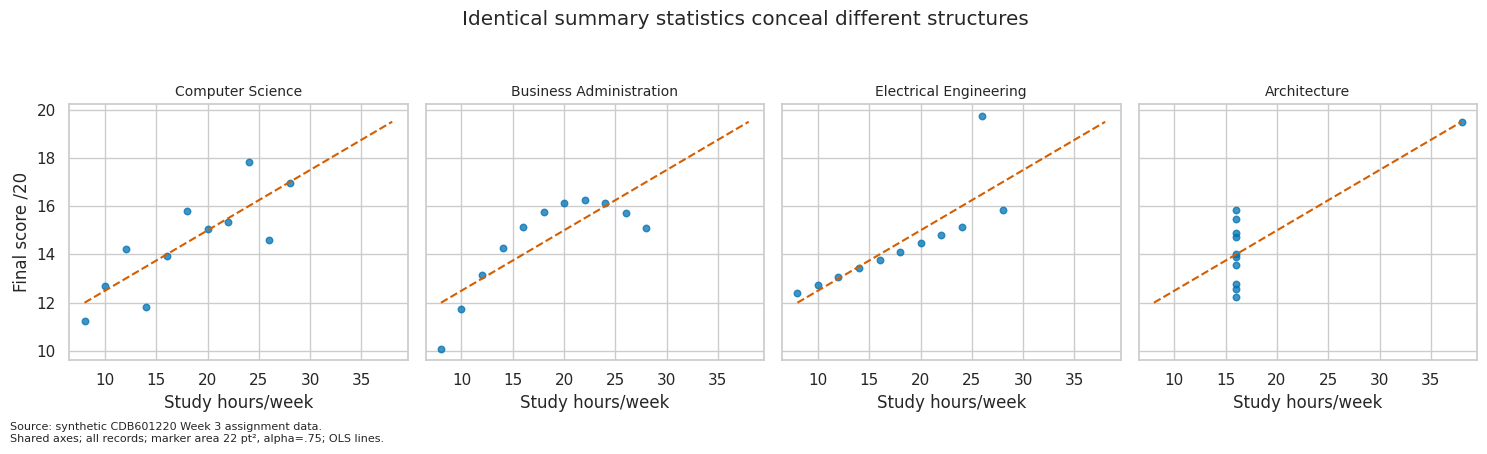

In [19]:
names = groups_data['department'].unique()
fig, ax = plt.subplots(1, len(names), figsize=(15, 4), sharex=True, sharey=True)
for a, name in zip(ax, names):
    group = groups_data.loc[groups_data['department'] == name]
    x = group['study_hours_per_week']
    y = group['final_score_out_of_20']
    regression = stats.linregress(x, y)
    grid = np.array([groups_data['study_hours_per_week'].min(), groups_data['study_hours_per_week'].max()])
    a.scatter(x, y, s=22, alpha=0.75, color=BLUE)
    a.plot(grid, regression.intercept + regression.slope * grid, color=ORANGE, linestyle='--')
    a.set(title=name, xlabel='Study hours/week')
    a.title.set_fontsize(10)
ax[0].set_ylabel('Final score /20')
fig.suptitle('Identical summary statistics conceal different structures', y=1.05)
fig.text(0.01, -0.03, SOURCE + '\n' + 'Shared axes; all records; marker area 22 pt², alpha=.75; OLS lines.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Quantify the high-leverage and outlier mechanisms

In [20]:
display(groups_data.groupby('department').study_hours_per_week.nunique())
ee = groups_data.loc[groups_data.department == 'Electrical Engineering']
ee_without_high = ee.loc[ee.final_score_out_of_20 < ee.final_score_out_of_20.max()]
print('Electrical Engineering r, all:', ee.study_hours_per_week.corr(ee.final_score_out_of_20))
print('Without the highest-score row:', ee_without_high.study_hours_per_week.corr(ee_without_high.final_score_out_of_20))
architecture = groups_data.loc[groups_data.department == 'Architecture']
display(architecture.study_hours_per_week.value_counts())

department
Architecture                2
Business Administration    11
Computer Science           11
Electrical Engineering     11
Name: study_hours_per_week, dtype: int64

Electrical Engineering r, all: 0.8162867394895985
Without the highest-score row: 0.9999965537848281


study_hours_per_week
16.0    10
38.0     1
Name: count, dtype: int64

### Answer

**Conclusion:** The table invites treating every group as equivalent.

**Decoy:** Small or unequal groups cannot explain the apparent agreement: each has n=11. Matching rounded summaries is not evidence of identical response patterns.

**Mechanism:** Anscombe-type non-identifiability: linear-looking scatter, curvature, an influential y outlier, and a high-leverage x observation can share summaries. Architecture: 2 distinct x values (largest tie 10/11); Business Administration: 11 distinct x values (largest tie 1/11); Computer Science: 11 distinct x values (largest tie 1/11); Electrical Engineering: 11 distinct x values (largest tie 1/11). The facets expose the structure that the table cannot identify.

**Redesign:** Small multiples use identical axes and show every observation; no group is reduced to a mean or correlation.

## A5. Matching statistics, different patterns
### Load the data

In [21]:
groups_data = pd.read_csv(DATA / 'case05_same_stats_shapes.csv')
display(groups_data.head())

,shape_name,hours_on_platform,assessment_score
0,straight line,27.331,34.870
1,straight line,27.561,55.234
2,straight line,27.792,62.224
3,straight line,28.023,59.030
4,straight line,28.254,38.094


### Calculate the complete published summary table

In [22]:
summary_rows = []
for name, group in groups_data.groupby('shape_name', sort=False):
    x = group['hours_on_platform']
    y = group['assessment_score']
    regression = stats.linregress(x, y)
    summary_rows.append({'group':name, 'n':len(group), 'mean_x':x.mean(),
        'mean_y':y.mean(), 'sd_x':x.std(ddof=0), 'sd_y':y.std(ddof=0),
        'Pearson_r':regression.rvalue, 'slope':regression.slope})
summary_table = pd.DataFrame(summary_rows).set_index('group').T
display(summary_table.round(6))

group,straight line,ring,star,two clusters,the letter X
n,180.000000,180.000000,180.000000,180.000000,180.000000
mean_x,48.000000,48.000017,47.999978,48.000022,48.000000
mean_y,63.000006,62.999994,62.999989,63.000017,62.999989
sd_x,12.000023,12.000002,11.999995,12.000007,11.999956
sd_y,14.999994,14.999999,15.000030,15.000002,14.999982
Pearson_r,0.419999,0.420003,0.419998,0.419997,0.419999
slope,0.524998,0.525004,0.524998,0.524996,0.524999


All five groups have n=180, means 48/63, population SDs 12/15, r≈0.420 and slope≈0.525. These summaries do not determine point-cloud geometry.

### Redesign: show every group on shared axes

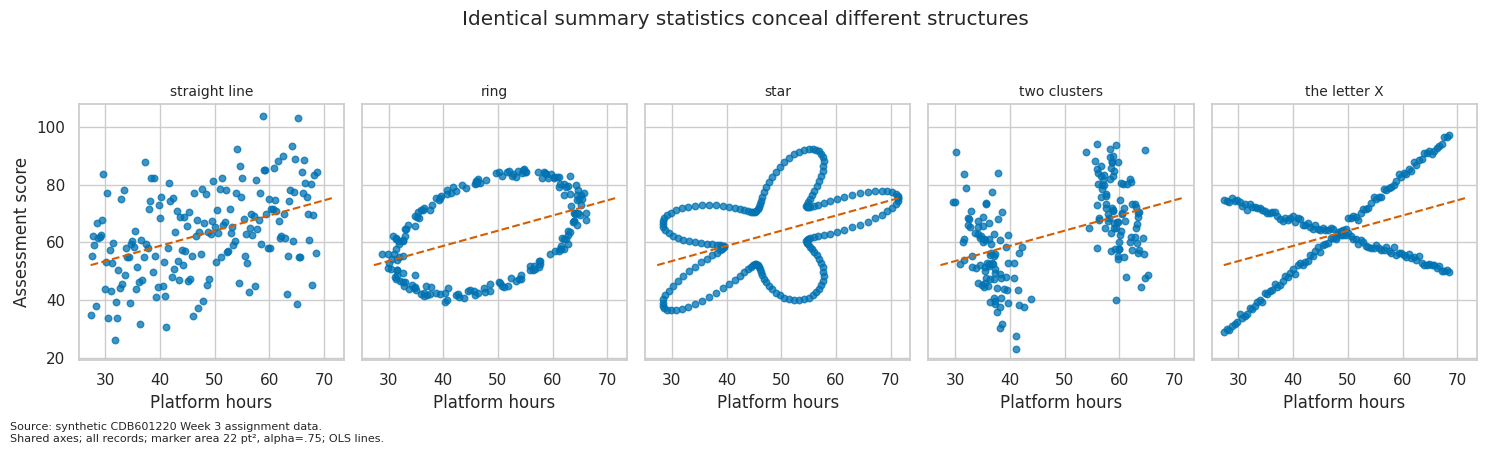

In [23]:
names = groups_data['shape_name'].unique()
fig, ax = plt.subplots(1, len(names), figsize=(15, 4), sharex=True, sharey=True)
for a, name in zip(ax, names):
    group = groups_data.loc[groups_data['shape_name'] == name]
    x = group['hours_on_platform']
    y = group['assessment_score']
    regression = stats.linregress(x, y)
    grid = np.array([groups_data['hours_on_platform'].min(), groups_data['hours_on_platform'].max()])
    a.scatter(x, y, s=22, alpha=0.75, color=BLUE)
    a.plot(grid, regression.intercept + regression.slope * grid, color=ORANGE, linestyle='--')
    a.set(title=name, xlabel='Platform hours')
    a.title.set_fontsize(10)
ax[0].set_ylabel('Assessment score')
fig.suptitle('Identical summary statistics conceal different structures', y=1.05)
fig.text(0.01, -0.03, SOURCE + '\n' + 'Shared axes; all records; marker area 22 pt², alpha=.75; OLS lines.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The table invites treating every group as equivalent.

**Decoy:** Sampling imbalance and tiny samples are ruled out by n=180 in every cohort. It is the insufficiency of low-order moments, not simply rounding, that hides the geometry.

**Mechanism:** Moment matching preserves different point-cloud geometries: straight line, ring, star, two clusters, the letter X. All five have n=180, means 48/63, population SDs 12/15, and r=0.420 (CSV rounding tolerance). The identical OLS slope is r*15/12 = 0.525; none of those moments identifies the shape. vizlib.match_stats demonstrates the construction.

**Redesign:** Small multiples use identical axes and show every observation; no group is reduced to a mean or correlation.

## A6. Sensor correlation heatmap
### Load the cohort

In [24]:
sensors = pd.read_csv(DATA / 'case06_sensor_matrix.csv')
display(sensors.head())
print(sensors.shape)

,systolic,diastolic,map_mmhg,resting_hr,vo2max,sleep_hours,deep_sleep_min,step_count,floors_climbed,hydration_index,...,age_years,probe_a,probe_b,probe_c,probe_d,probe_e,probe_f,age_band,study_site,hr_device_model
0,166.0,101.0,122.4,71.0,47.9,6.18,339.0,7304.0,18.1,21.9,...,30.0,0.914,-0.169,0.683,-1.595,-1.043,-1.508,<30,Site C,DX-300
1,105.0,62.0,76.3,79.0,52.7,7.79,428.0,4469.0,8.0,69.3,...,58.0,-2.058,-0.193,1.365,-1.436,0.103,0.949,45-59,Site D,DX-400
2,147.0,92.0,110.5,73.0,57.9,6.72,342.0,9619.0,24.0,12.5,...,40.0,0.643,0.361,-0.219,0.566,1.539,-0.139,30-44,Site D,DX-400
3,123.0,76.0,91.7,60.0,33.2,7.07,356.0,3052.0,7.4,97.7,...,50.0,-1.011,2.388,0.343,0.127,-0.099,1.120,45-59,Site A,DX-100
4,152.0,81.0,104.7,77.0,51.4,6.55,354.0,4592.0,9.7,71.3,...,51.0,1.337,2.004,-1.239,0.301,-0.946,0.925,45-59,Site D,DX-400


(180, 23)


### Calculate the analyst’s 20-variable matrix

In [25]:
sensor_corr = sensors.drop(columns=['age_band', 'study_site', 'hr_device_model']).corr()
print('Matrix shape:', sensor_corr.shape)
print('Creatinine–HbA1c:', sensor_corr.loc['creatinine', 'hba1c'])
print('Systolic–MAP:', sensor_corr.loc['systolic', 'map_mmhg'])
assert sensor_corr.shape == (20, 20)

Matrix shape: (20, 20)
Creatinine–HbA1c: 0.7651666421647184
Systolic–MAP: 0.9583647744991359


### Reproduce the flawed heatmap

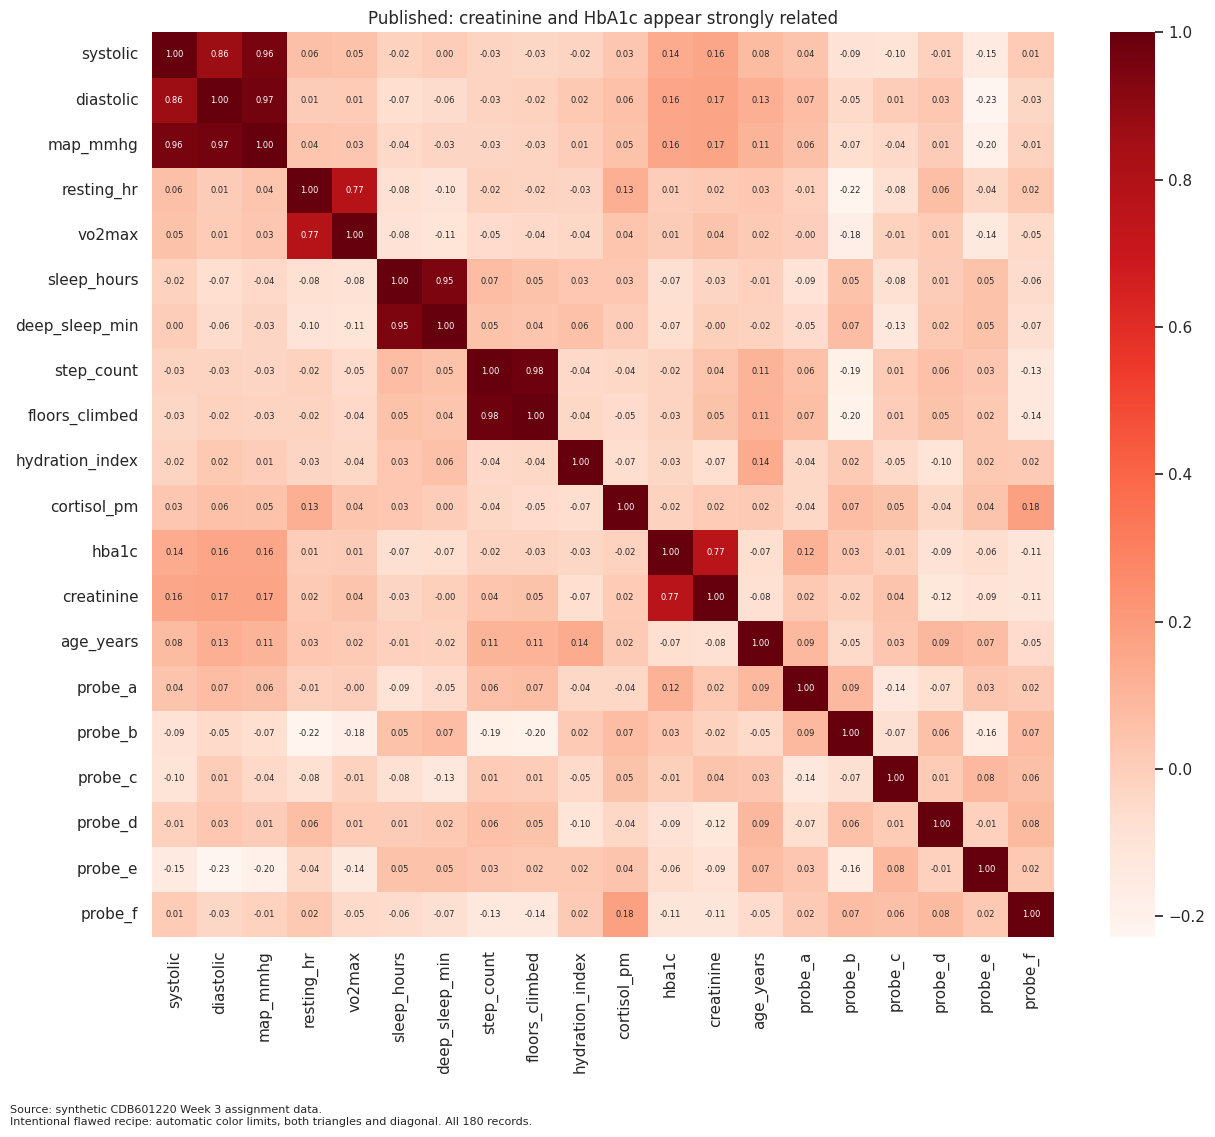

In [26]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(sensor_corr, cmap='Reds', annot=True, fmt='.2f',
            annot_kws={'size':6}, ax=ax)
ax.set_title('Published: creatinine and HbA1c appear strongly related')
fig.text(0.01, -0.03, SOURCE + '\n' + 'Intentional flawed recipe: automatic color limits, both triangles and diagonal. All 180 records.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Test the influence of the extreme observation

In [27]:
extreme_index = sensors.creatinine.idxmax()
display(sensors.loc[[extreme_index], ['creatinine', 'hba1c', 'age_band']])
sensitivity = sensors.drop(index=extreme_index)
print('All 180 rows r:', sensors.creatinine.corr(sensors.hba1c))
print('Sensitivity, 179 rows r:', sensitivity.creatinine.corr(sensitivity.hba1c))
for age, group in sensitivity.groupby('age_band'):
    print(age, ': within-age r =', round(group.creatinine.corr(group.hba1c), 3))

,creatinine,hba1c,age_band
0,1050.0,15.8,<30


All 180 rows r: 0.7651666421647183
Sensitivity, 179 rows r: -0.0036223014464872296
30-44 : within-age r = -0.102
45-59 : within-age r = -0.091
60+ : within-age r = 0.065
<30 : within-age r = 0.385


### Redesign: signed scales and the actual scatter

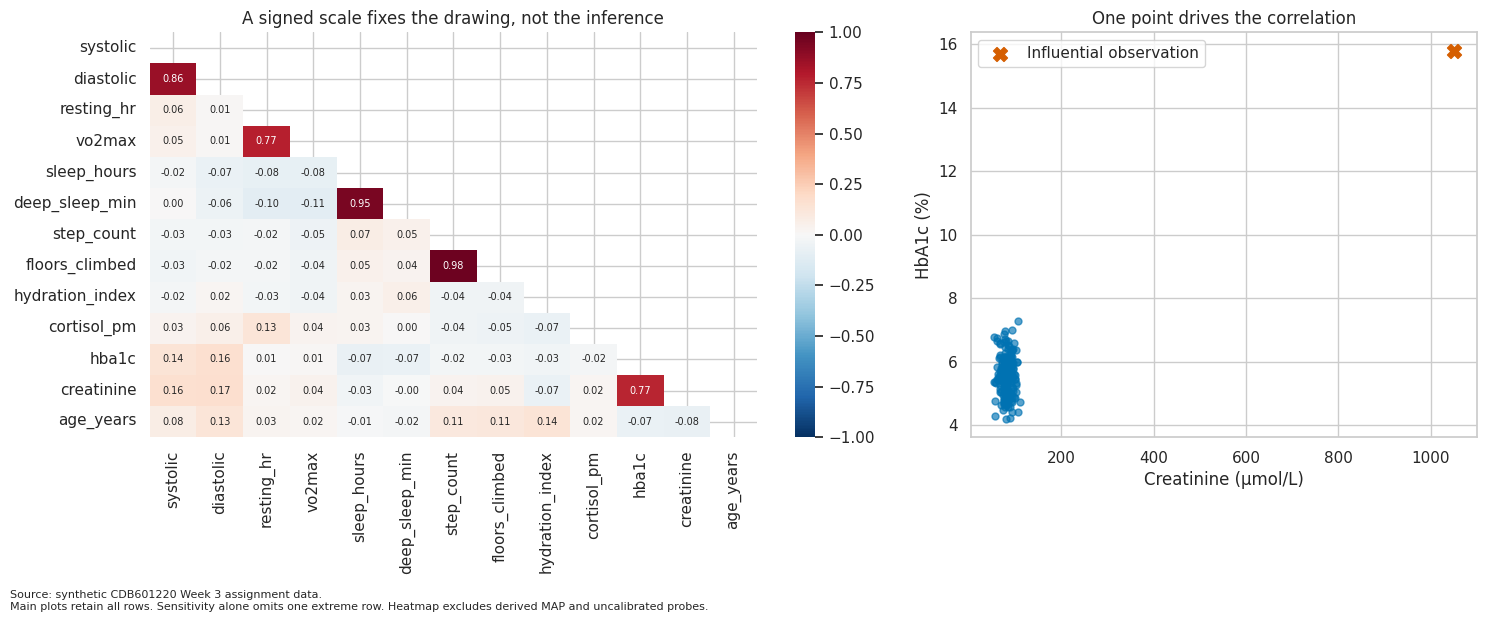

In [28]:
measured = [c for c in sensor_corr if c != 'map_mmhg' and not c.startswith('probe_')]
measured_corr = sensors[measured].corr()
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios':[1.5, 1]})
sns.heatmap(measured_corr, mask=np.triu(np.ones_like(measured_corr, dtype=bool)),
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size':7}, ax=ax[0])
ax[0].set_title('A signed scale fixes the drawing, not the inference')
ax[1].scatter(sensors.creatinine, sensors.hba1c, color=BLUE, s=25, alpha=.65)
ax[1].scatter(sensors.loc[extreme_index, 'creatinine'], sensors.loc[extreme_index, 'hba1c'],
              marker='X', s=100, color=ORANGE, label='Influential observation')
ax[1].set(xlabel='Creatinine (µmol/L)', ylabel='HbA1c (%)', title='One point drives the correlation')
ax[1].legend()
fig.text(0.01, -0.03, SOURCE + '\n' + 'Main plots retain all rows. Sensitivity alone omits one extreme row. Heatmap excludes derived MAP and uncalibrated probes.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The analyst presents high creatinine-HbA1c correlation as a stable physiological finding.

**Decoy:** Age-group mixing is a plausible first guess, but removing just the extreme row collapses the overall correlation; within-age correlations without it are 30-44: -0.102, 45-59: -0.091, 60+: 0.065, <30: 0.385.

**Mechanism:** Influence/leverage: row 1 has creatinine 1050.0 and HbA1c 15.80. Pearson r is 0.765 with it and -0.004 without it. MAP-systolic r=0.958 is additionally inflated by arithmetic derivation. The Reds auto-scale hides correlation sign and duplicates pairs; fixing its scale cannot cure influence, derived-variable dependence, site/device confounding, or multiple screening of 190 pairs.

**Redesign:** Use a signed, fixed-scale triangular heatmap of measured variables plus a scatter that exposes the influential observation. Report sensitivity without declaring the extreme row invalid.

## A7. The false financial crossover
### Load the six months

In [29]:
finance = pd.read_csv(DATA / 'case07_dual_axis_series.csv')
display(finance)

,month,revenue_pkr_m,cost_pkr_m
0,Jan,52,44
1,Feb,58,46
2,Mar,61,47
3,Apr,66,49
4,May,71,51
5,Jun,78,53


The brief explicitly requests this bad-chart reproduction despite its general ban on dual axes. Two axes are used **only to demonstrate the flawed recipe**; the recommended chart uses one shared scale.

### Reproduce the misleading chart

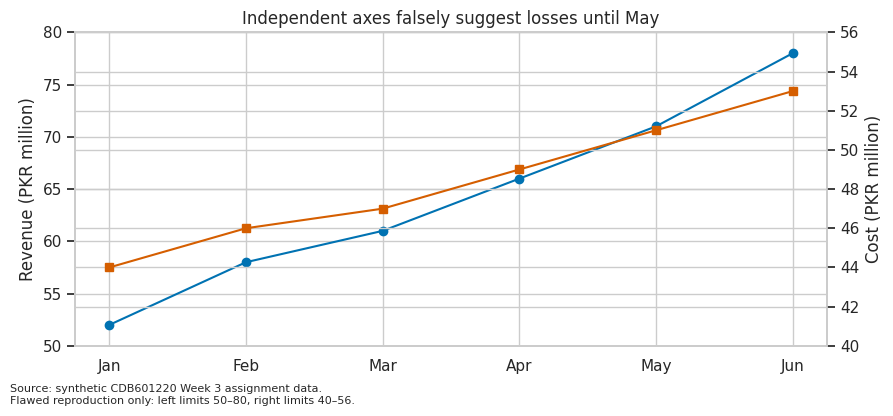

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
right = ax.twinx()
ax.plot(finance.month, finance.revenue_pkr_m, marker='o', color=BLUE)
right.plot(finance.month, finance.cost_pkr_m, marker='s', color=ORANGE)
ax.set(ylim=(50, 80), ylabel='Revenue (PKR million)', title='Independent axes falsely suggest losses until May')
right.set(ylim=(40, 56), ylabel='Cost (PKR million)')
fig.text(0.01, -0.03, SOURCE + '\n' + 'Flawed reproduction only: left limits 50–80, right limits 40–56.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Compare visual heights with the actual profits

In [31]:
finance['revenue_plot_height'] = (finance.revenue_pkr_m - 50) / 30
finance['cost_plot_height'] = (finance.cost_pkr_m - 40) / 16
finance['profit_pkr_m'] = finance.revenue_pkr_m - finance.cost_pkr_m
display(finance)
assert (finance.cost_plot_height.iloc[:4] > finance.revenue_plot_height.iloc[:4]).all()
assert (finance.profit_pkr_m > 0).all()

,month,revenue_pkr_m,cost_pkr_m,revenue_plot_height,cost_plot_height,profit_pkr_m
0,Jan,52,44,0.066667,0.2500,8
1,Feb,58,46,0.266667,0.3750,12
2,Mar,61,47,0.366667,0.4375,14
3,Apr,66,49,0.533333,0.5625,17
4,May,71,51,0.700000,0.6875,20
5,Jun,78,53,0.933333,0.8125,25


### Redesign: one scale for the same currency unit

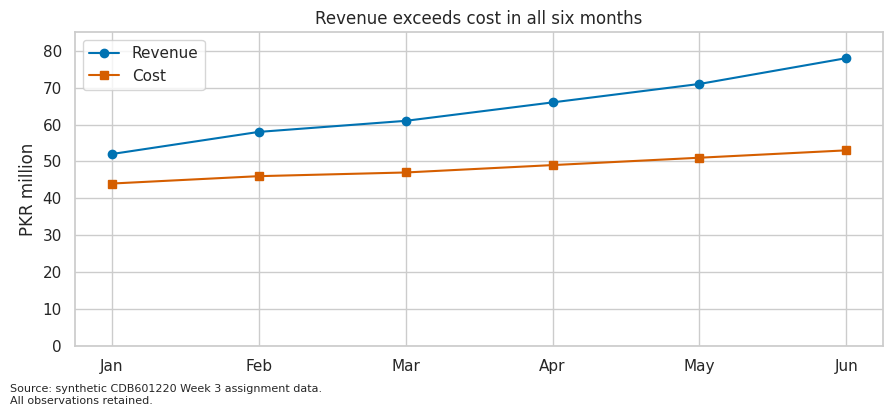

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(finance.month, finance.revenue_pkr_m, marker='o', color=BLUE, label='Revenue')
ax.plot(finance.month, finance.cost_pkr_m, marker='s', color=ORANGE, label='Cost')
ax.set(ylim=(0, 85), ylabel='PKR million', title='Revenue exceeds cost in all six months')
ax.legend()
fig.text(0.01, -0.03, SOURCE + '\n' + 'All observations retained.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** Vertical ordering invites a claim of losses in January-April and a break-even crossover in May.

**Decoy:** The issue is not correlation or missing months: both series have six values and are already expressed in the same currency unit.

**Mechanism:** Independent affine mappings destroy comparability: revenue height is (R-50)/30, cost height (C-40)/16. Cost has greater plotted height in the first four months, despite actual monthly profits of [8, 12, 14, 17, 20, 25] PKR million. A crossover can be moved merely by choosing other axis limits.

**Redesign:** Use one shared axis, since both quantities are PKR millions. The brief conflicts with itself: the case-specific reproduction requests twinx although the general rule prohibits it; it is used only for the labeled bad-chart reconstruction.

## A8. Histogram binning
### Load all 10,000 systolic readings

In [33]:
vitals = pd.read_csv(DATA / 'vitals_10k.csv')
systolic = vitals.systolic
display(systolic.describe())
assert len(systolic) == 10000

count    10000.000000
mean       137.656700
std         22.597192
min         92.000000
25%        119.000000
50%        128.000000
75%        160.000000
max        199.000000
Name: systolic, dtype: float64

### Reproduce three very different-looking histograms

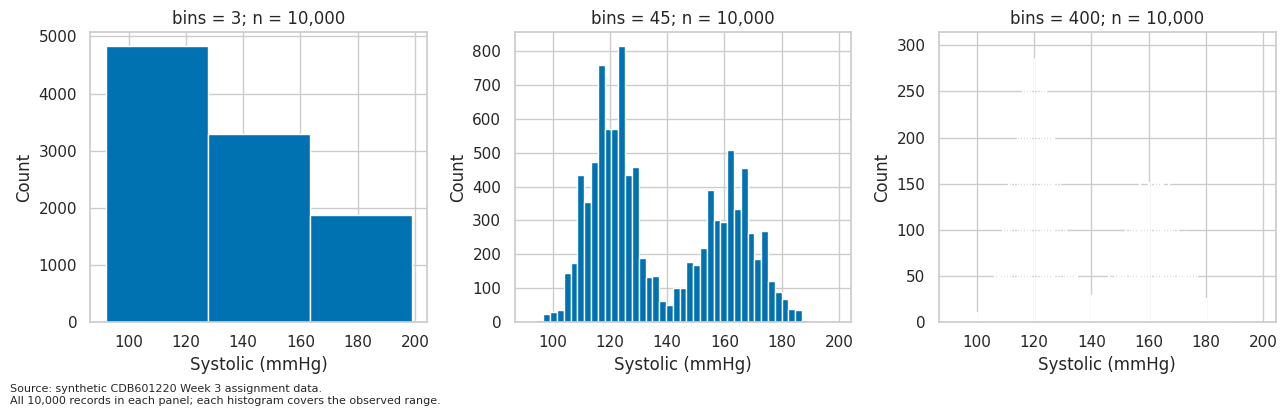

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, bins in zip(ax, [3, 45, 400]):
    a.hist(systolic, bins=bins, color=BLUE)
    a.set(title=f'bins = {bins}; n = {len(systolic):,}', xlabel='Systolic (mmHg)', ylabel='Count')
fig.text(0.01, -0.03, SOURCE + '\n' + 'All 10,000 records in each panel; each histogram covers the observed range.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Quantify the resolution problem

In [35]:
observed_range = systolic.max() - systolic.min()
print('3-bin width:', observed_range / 3, 'mmHg')
print('400-bin width:', observed_range / 400, 'mmHg')
fd_width = 2 * (systolic.quantile(.75) - systolic.quantile(.25)) * len(systolic)**(-1/3)
print('Freedman–Diaconis width:', fd_width, 'mmHg')
print('All recorded values are integers:', np.equal(systolic, systolic.astype(int)).all())

3-bin width: 35.666666666666664 mmHg
400-bin width: 0.2675 mmHg
Freedman–Diaconis width: 3.806102843562479 mmHg
All recorded values are integers: True


### Redesign: test sensible widths on shared scales

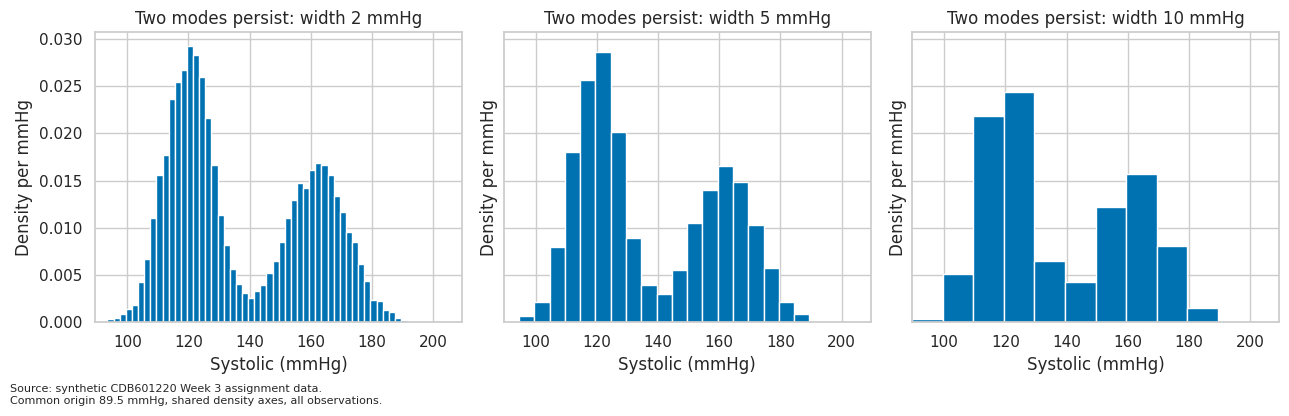

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for a, width in zip(ax, [2, 5, 10]):
    edges = np.arange(89.5, 209.5 + width, width)
    a.hist(systolic, bins=edges, density=True, color=BLUE)
    a.set(xlim=(89.5, 209.5), xlabel='Systolic (mmHg)', ylabel='Density per mmHg',
          title=f'Two modes persist: width {width} mmHg')
fig.text(0.01, -0.03, SOURCE + '\n' + 'Common origin 89.5 mmHg, shared density axes, all observations.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The three panels invite three incompatible stories about the same distribution.

**Decoy:** Different samples and data cleaning are ruled out: all panels have n=10,000, min=92, max=199.

**Mechanism:** Aggregation scale and integer quantization: 3 bins merge modes (width 35.67 mmHg), while 400 bins use width 0.268, below the 1-mmHg recording resolution, creating empty-bin combs. The Freedman-Diaconis width is 3.81 mmHg; nearby sensible widths retain the low/high-pressure modes.

**Redesign:** Compare explicit 2/5/10-mmHg widths on shared density axes; 5 mmHg is the clinical-review choice.

## A9. Density beyond 100% saturation
### Load SpO₂ and check the physical boundary

In [37]:
spo2 = pd.read_csv(DATA / 'vitals_10k.csv').spo2
print('Maximum:', spo2.max())
print('Observed readings above 100:', (spo2 > 100).sum())
print('Readings exactly 100:', (spo2 == 100).sum())

Maximum: 100
Observed readings above 100: 0
Readings exactly 100: 304


### Integrate the unbounded Gaussian tail

In [38]:
kde = stats.gaussian_kde(spo2, bw_method='scott')
mass_above_100 = kde.integrate_box_1d(100, np.inf)
print(f'Estimated probability above 100% = {100 * mass_above_100:.4f}%')
print('The supplied data give about 1.56%, not the 4.4% in the assignment title.')

Estimated probability above 100% = 1.5645%
The supplied data give about 1.56%, not the 4.4% in the assignment title.


### Reproduce the default-bandwidth KDE

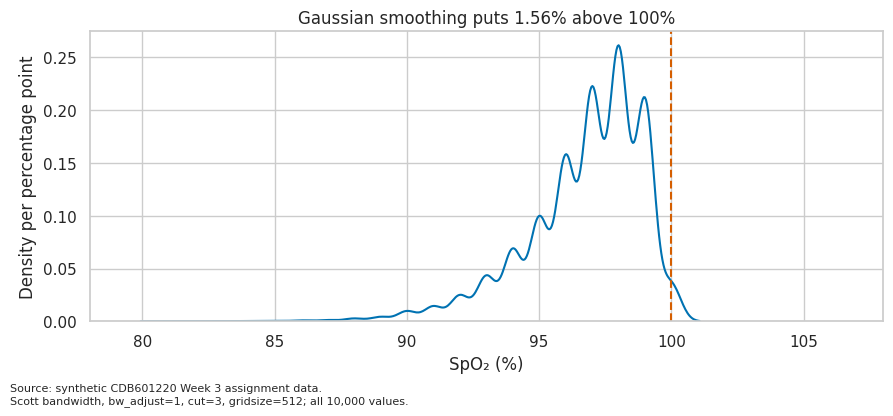

In [39]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(x=spo2, bw_method='scott', bw_adjust=1, cut=3, gridsize=512, color=BLUE, ax=ax)
ax.axvline(100, color=ORANGE, linestyle='--')
ax.set(xlim=(78, 108), xlabel='SpO₂ (%)', ylabel='Density per percentage point',
       title=f'Gaussian smoothing puts {100 * mass_above_100:.2f}% above 100%')
fig.text(0.01, -0.03, SOURCE + '\n' + 'Scott bandwidth, bw_adjust=1, cut=3, gridsize=512; all 10,000 values.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Redesign: observed frequencies and the empirical CDF

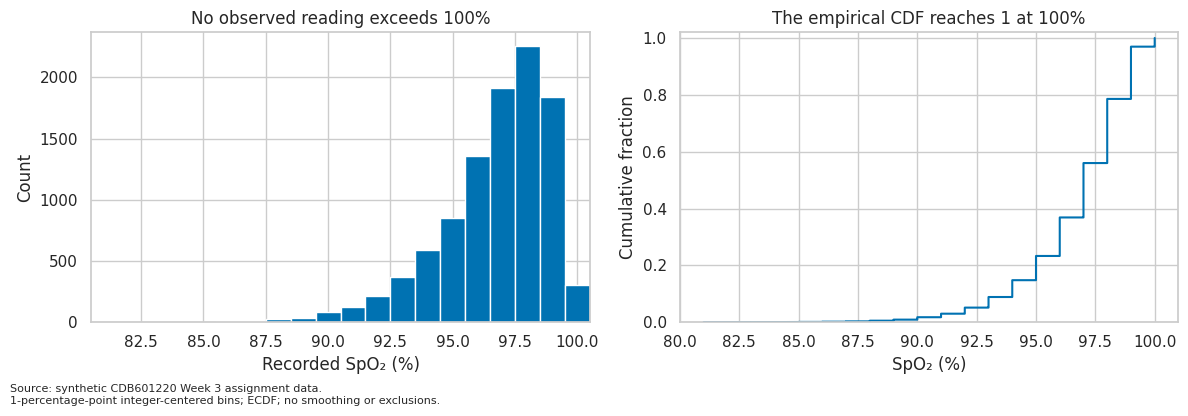

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(spo2, bins=np.arange(-.5, 101.5, 1), color=BLUE)
ax[0].set(xlim=(80.5, 100.5), xlabel='Recorded SpO₂ (%)', ylabel='Count',
          title='No observed reading exceeds 100%')
ordered = np.sort(spo2)
ax[1].step(ordered, np.arange(1, len(ordered)+1)/len(ordered), where='post', color=BLUE)
ax[1].set(xlim=(80, 101), ylim=(0, 1.02), xlabel='SpO₂ (%)', ylabel='Cumulative fraction',
          title='The empirical CDF reaches 1 at 100%')
fig.text(0.01, -0.03, SOURCE + '\n' + '1-percentage-point integer-centered bins; ECDF; no smoothing or exclusions.', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

### Answer

**Conclusion:** The KDE can be misread as evidence of readings above 100% saturation.

**Decoy:** Impossible recorded measurements are ruled out: max=100%, count above 100=0, and 304 records are exactly 100%.

**Mechanism:** Boundary bias: symmetric Gaussian kernels assign mass outside the bounded measurement support. Integrating the fitted Scott KDE gives 0.01565 (1.56%) above 100, although the empirical fraction is zero. The supplied case title says 4.4%, but this ZIP and the specified default Scott bandwidth produce 1.56%; no bandwidth was tuned to force that title. The stated self-check (observed maximum 100, curve beyond it) does pass. Clipping the drawing or cut=0 hides the leakage but does not correct or renormalize the density.

**Redesign:** Use an integer-aligned histogram and an unsmoothed ECDF; distinguish observed frequencies from a model density.